# 4. Reduktion des Netzwerks

Grundlage ist das vollständige Athletennetzwerk aus `../data/processed/networks/athletes.gexf`. Eine Kante verbindet zwei Athleten mit mindestens einem gemeinsamen Veranstaltungstag; `weight` zählt die verschiedenen gemeinsamen Veranstaltungstage ihrer gespeicherten Bestleistungen.

Wir prüfen die Ausgangsgrösse, untersuchen die Gewichte und vergleichen die Mindestgewichte **1, 2, 3, 5 und 10**. Bei jeder Reduktion bleiben alle Knoten erhalten. Entfernt werden ausschliesslich Kanten unterhalb des Thresholds. Die Giant Component des vollständigen Graphen wird separat bestimmt.

Auf dem gewählten Arbeitsnetz folgen eine **Local View** nach Geschlecht, eine **Global View** nach Profilnation, eine **Contextual View** für die Schweiz und das **Ego-Netzwerk** von Michael Phelps.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
GRAPH_PATH = PROJECT_ROOT / 'data/processed/networks/athletes.gexf'
EVENTS_PATH = PROJECT_ROOT / 'data/processed/networks/athlete_events.parquet'
NATIONS_PATH = PROJECT_ROOT / 'data/processed/networks/nations.gexf'
REPORT_DIR = PROJECT_ROOT / 'Report/graphics'
THRESHOLDS = [1, 2, 3, 5, 10]
COLOR = '#367da2'
MUTED = '#a3a29d'
SEED = 42
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 4.1 Vollständigen Graphen laden und prüfen

Der Graph wird einmal geladen. Wir prüfen, dass er einfach, ungerichtet und ohne Selbstschleifen ist. Alle Gewichte müssen endliche, positive Ganzzahlen sein, da sie Veranstaltungstage zählen.

In [2]:
G = nx.read_gexf(GRAPH_PATH)
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()

assert not G.is_directed(), 'Das Athletennetzwerk muss ungerichtet sein.'
assert not G.is_multigraph(), 'Es wird ein einfacher Graph erwartet.'
assert n_nodes > 0 and n_edges > 0, 'Die Graphdatei enthält kein auswertbares Netzwerk.'
assert nx.number_of_selfloops(G) == 0, 'Selbstschleifen sind im Athletenmodell nicht vorgesehen.'

# Direkt ein numerisches Array erzeugen, ohne eine grosse Python-Liste anzulegen.
weights = pd.Series(
    np.fromiter(
        (data.get('weight', np.nan) for _, _, data in G.edges(data=True)),
        dtype=np.float64, count=n_edges,
    ),
    name='weight',
)
assert np.isfinite(weights.to_numpy()).all(), 'Fehlende oder nicht endliche Kantengewichte.'
assert (weights >= 1).all(), 'Alle Kantengewichte müssen mindestens 1 sein.'
assert (weights == np.floor(weights)).all(), 'Kantengewichte müssen ganze Tage zählen.'

# Nach der Prüfung als ganzzahlige Zählwerte verwenden.
weights = weights.astype('int64')
display(pd.Series({
    'Knoten (Athleten)': n_nodes,
    'Kanten (Athletenpaare)': n_edges,
    'Selbstschleifen': nx.number_of_selfloops(G),
}, name='Anzahl').to_frame())

,Anzahl
Knoten (Athleten),13156
Kanten (Athletenpaare),1231245
Selbstschleifen,0


### Giant Component des vollständigen Graphen

Connected Components werden nacheinander ausgewertet. Wir behalten nur die jeweils grösste Knotenmenge; isolierte Knoten zählen als Komponenten der Grösse 1. Der Giant-Component-Anteil bezieht sich auf **alle Knoten**, einschliesslich isolierter Athleten.

`G_giant` ist eine separate Subgraphansicht. Der vollständige Graph `G` bleibt die Grundlage für sämtliche Threshold-Vergleiche.

In [3]:
def component_summary(graph):
    """Komponenten eines einfachen, schleifenfreien Graphen ohne Komponentenliste zählen."""
    n_components = 0
    n_isolates = 0
    giant_nodes = set()
    for component in nx.connected_components(graph):
        n_components += 1
        size = len(component)
        n_isolates += int(size == 1)
        if size > len(giant_nodes):
            giant_nodes = component

    return {
        'isolates': n_isolates,
        'components': n_components,
        'giant_component_nodes': len(giant_nodes),
        'giant_component_share': len(giant_nodes) / len(graph) if len(graph) else 0.0,
    }, giant_nodes


full_summary, full_giant_nodes = component_summary(G)
G_giant = G.subgraph(full_giant_nodes)

display(pd.DataFrame([{
    'Isolierte Knoten': full_summary['isolates'],
    'Connected Components': full_summary['components'],
    'Knoten der Giant Component': len(G_giant),
    'GC-Anteil an allen Knoten': f"{full_summary['giant_component_share']:.2%}",
    'Knoten ausserhalb der Giant Component': n_nodes - len(G_giant),
}], index=['Vollständiger Graph']))

,Isolierte Knoten,Connected Components,Knoten der Giant Component,GC-Anteil an allen Knoten,Knoten ausserhalb der Giant Component
Vollständiger Graph,20,23,13132,99.82%,24


## 4.2 Verteilung der Kantengewichte

Jede Kante geht einmal in die Verteilung ein. Die Kennzahlen beschreiben gemeinsame Veranstaltungstage pro verbundenem Athletenpaar. Neben Mittelwert, Standardabweichung und Median zeigen wir Quantile bis zum 99. Perzentil sowie die Häufigkeit jedes Gewichts.

In [4]:
weight_summary = weights.describe().rename(index={
    'count': 'Anzahl Kanten', 'mean': 'Mittelwert', 'std': 'Standardabweichung',
    'min': 'Minimum', '25%': '25%-Quantil', '50%': 'Median',
    '75%': '75%-Quantil', 'max': 'Maximum',
}).to_frame('Gewicht')
display(weight_summary.round(3))

quantiles = weights.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
quantiles.index = [f'{q:.0%}' for q in quantiles.index]
quantiles.index.name = 'Quantil'
display(quantiles.to_frame('Gemeinsame Veranstaltungstage').round(2))

weight_frequency = weights.value_counts().sort_index().rename('Kanten').to_frame()
weight_frequency.index.name = 'Gewicht (gemeinsame Tage)'
weight_frequency['Anteil'] = weight_frequency['Kanten'] / n_edges
frequency_display = weight_frequency.copy()
frequency_display['Anteil'] = frequency_display['Anteil'].map('{:.2%}'.format)
display(frequency_display)

,Gewicht
Anzahl Kanten,1231245.000
Mittelwert,1.511
Standardabweichung,1.081
Minimum,1.000
25%-Quantil,1.000
Median,1.000
75%-Quantil,2.000
Maximum,25.000


,Gemeinsame Veranstaltungstage
Quantil,
25%,1.0
50%,1.0
75%,2.0
90%,3.0
95%,4.0
99%,6.0


,Kanten,Anteil
Gewicht (gemeinsame Tage),,
1,874026,70.99%
2,221866,18.02%
3,72329,5.87%
4,29582,2.40%
5,14934,1.21%
6,8304,0.67%
7,4761,0.39%
8,2573,0.21%
9,1367,0.11%


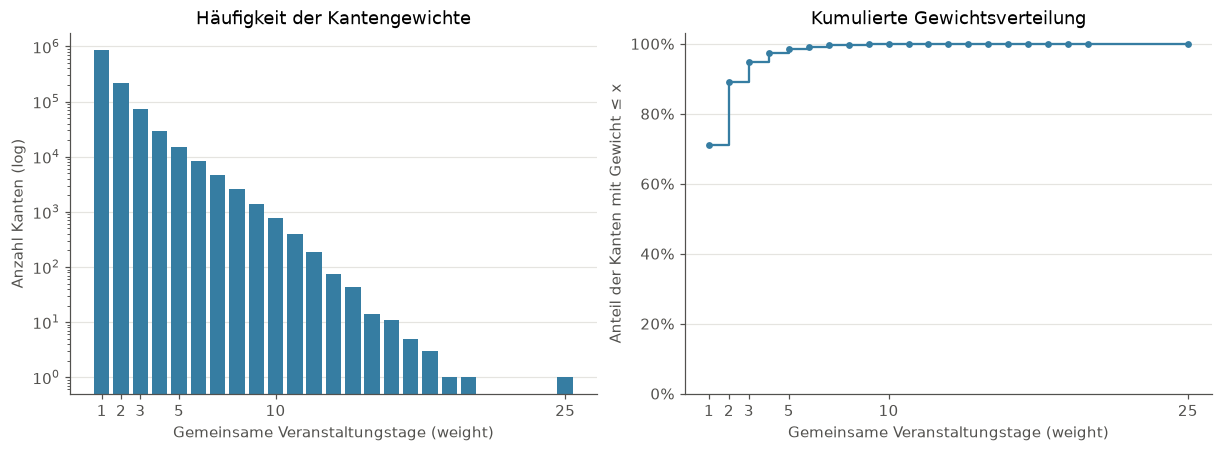

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')

axes[0].bar(weight_frequency.index, weight_frequency['Kanten'],
            color=COLOR, width=0.8)
axes[0].set_yscale('log')
axes[0].set(xlabel='Gemeinsame Veranstaltungstage (weight)', ylabel='Anzahl Kanten (log)',
            title='Häufigkeit der Kantengewichte')

cumulative_share = weight_frequency['Anteil'].cumsum()
axes[1].step(cumulative_share.index, cumulative_share, where='post', color=COLOR)
axes[1].scatter(cumulative_share.index, cumulative_share, color=COLOR, s=12)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(xlabel='Gemeinsame Veranstaltungstage (weight)',
            ylabel='Anteil der Kanten mit Gewicht ≤ x', ylim=(0, 1.03),
            title='Kumulierte Gewichtsverteilung')

for ax in axes:
    ax.set_xticks(sorted(set(THRESHOLDS + [int(weights.max())])))
    ax.grid(axis='x', visible=False)
plt.show()

Die Häufigkeiten fallen mit steigenden Gewichten stark ab. Die logarithmische Achse macht auch seltene hohe Gewichte sichtbar. Median und oberes Quartil zeigen, ob sich ein Grossteil der Kanten auf wenige gemeinsame Tage beschränkt. Ein höheres Mindestgewicht behält wiederholt beobachtete gemeinsame Tage bei; es belegt keine persönliche Bekanntschaft.

## 4.3 Weight-Thresholds vergleichen

Eine Kante bleibt genau dann erhalten, wenn `weight >= min_weight`. Alle Athleten bleiben im Graphen, auch wenn sie nach dem Filtern isoliert sind. Die GC-Anteile haben dadurch für alle Thresholds denselben Nenner.

Kantenfilter werden als `subgraph_view` erstellt: Sie teilen die Daten mit `G` und benötigen keine Kopie der Kantenattribute. Für Threshold 1 verwenden wir die bereits berechneten Komponenten des vollständigen Graphen. Die Kantenanzahl ergibt sich direkt aus dem einmal eingelesenen Gewichtsarray.

In [6]:
rows = []
for threshold in THRESHOLDS:
    if threshold == 1:
        H = G
        summary = full_summary.copy()
    else:
        H = nx.subgraph_view(
            G,
            filter_edge=lambda u, v, minimum=threshold: G[u][v]['weight'] >= minimum,
        )
        summary, _ = component_summary(H)

    rows.append({
        'min_weight': threshold,
        'nodes': H.number_of_nodes(),
        'edges': int(weights.ge(threshold).sum()),
        **summary,
    })
    del H

comparison = pd.DataFrame(rows).set_index('min_weight')
comparison['edge_share'] = comparison['edges'] / n_edges
comparison = comparison[[
    'nodes', 'edges', 'edge_share', 'isolates', 'components',
    'giant_component_nodes', 'giant_component_share',
]]

# Kontrollieren, dass ausschliesslich Kanten reduziert wurden.
assert comparison['nodes'].eq(n_nodes).all()
assert comparison.loc[1, 'edges'] == n_edges
assert comparison['edges'].is_monotonic_decreasing
assert comparison['isolates'].is_monotonic_increasing
assert comparison['components'].is_monotonic_increasing
assert comparison['giant_component_nodes'].is_monotonic_decreasing
assert comparison['giant_component_nodes'].le(n_nodes).all()
assert G.number_of_nodes() == n_nodes and G.number_of_edges() == n_edges

comparison_display = comparison.copy()
for column in ['edge_share', 'giant_component_share']:
    comparison_display[column] = comparison_display[column].map('{:.2%}'.format)
comparison_display = comparison_display.rename(columns={
    'nodes': 'Knoten', 'edges': 'Kanten', 'edge_share': 'Kantenanteil am Vollgraphen',
    'isolates': 'Isolierte Knoten', 'components': 'Connected Components',
    'giant_component_nodes': 'GC-Knoten', 'giant_component_share': 'GC-Anteil an allen Knoten',
})
comparison_display.index = [f'≥ {value}' for value in comparison_display.index]
comparison_display.index.name = 'Mindestgewicht'
display(comparison_display)

,Knoten,Kanten,Kantenanteil am Vollgraphen,Isolierte Knoten,Connected Components,GC-Knoten,GC-Anteil an allen Knoten
Mindestgewicht,,,,,,,
≥ 1,13156,1231245,100.00%,20,23,13132,99.82%
≥ 2,13156,357219,29.01%,413,428,12709,96.60%
≥ 3,13156,135353,10.99%,1771,1835,11209,85.20%
≥ 5,13156,33442,2.72%,6188,6432,5416,41.17%
≥ 10,13156,1503,0.12%,11915,12168,95,0.72%


## 4.4 Einfluss auf Kantenzahl und Zusammenhalt

Die linke Abbildung zeigt die verbleibenden Kanten, die rechte den Anteil aller Athleten in der Giant Component. Die x-Achse verwendet die tatsächlichen Mindestgewichte. Die Prozentangaben links beziehen sich auf die ursprüngliche Kantenanzahl.

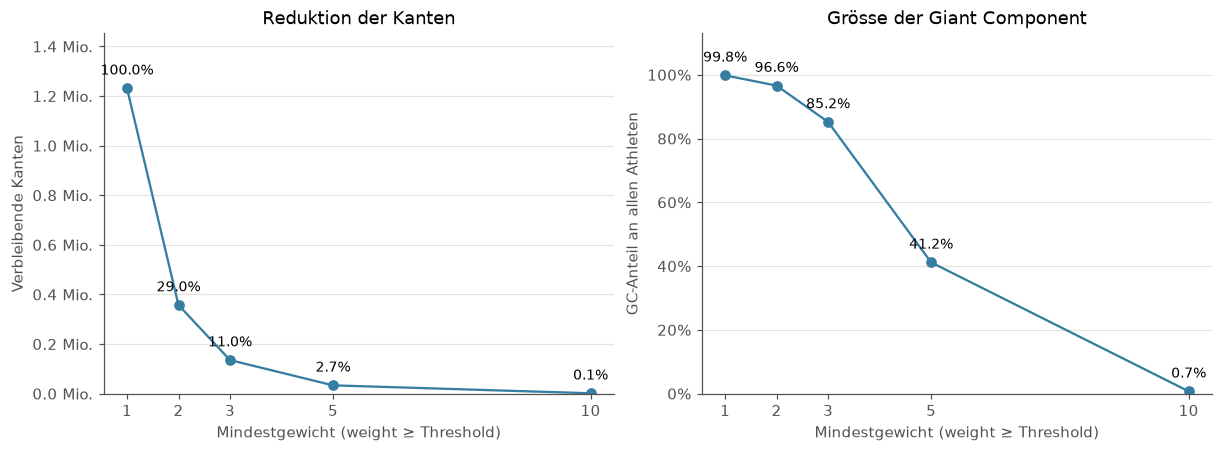

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')

axes[0].plot(comparison.index, comparison['edges'], marker='o', color=COLOR)
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:.1f} Mio.')
)
axes[0].set(xlabel='Mindestgewicht (weight ≥ Threshold)', ylabel='Verbleibende Kanten',
            ylim=(0, n_edges * 1.18), title='Reduktion der Kanten')
for threshold, row in comparison.iterrows():
    axes[0].annotate(f"{row['edge_share']:.1%}",
                     (threshold, row['edges']), xytext=(0, 9),
                     textcoords='offset points', ha='center', fontsize=9)

axes[1].plot(comparison.index, comparison['giant_component_share'],
             marker='o', color=COLOR)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(xlabel='Mindestgewicht (weight ≥ Threshold)',
            ylabel='GC-Anteil an allen Athleten', ylim=(0, 1.13),
            title='Grösse der Giant Component')
for threshold, row in comparison.iterrows():
    axes[1].annotate(f"{row['giant_component_share']:.1%}",
                     (threshold, row['giant_component_share']), xytext=(0, 9),
                     textcoords='offset points', ha='center', fontsize=9)

for ax in axes:
    ax.set_xticks(THRESHOLDS)
    ax.grid(axis='x', visible=False)
plt.show()

### Abbildung für den Report

Die beiden Auswertungen oben werden für den Report in einer Abbildung zusammengefasst: links die Gewichtsverteilung, rechts die Wirkung der Mindestgewichte.

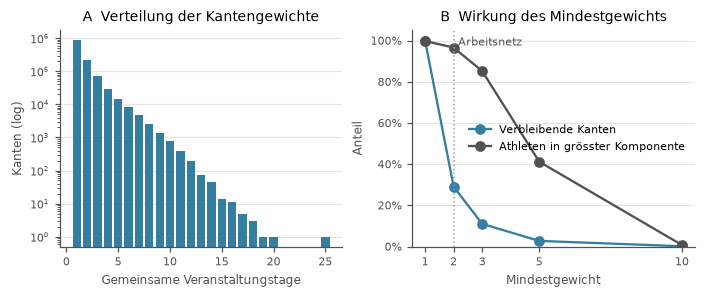

In [8]:
with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6), layout='constrained')
    axes[0].bar(weight_frequency.index, weight_frequency['Kanten'], color=COLOR, width=0.8)
    axes[0].set_yscale('log')
    axes[0].set(title='A  Verteilung der Kantengewichte',
                xlabel='Gemeinsame Veranstaltungstage', ylabel='Kanten (log)')

    for column, label, color in [('edge_share', 'Verbleibende Kanten', COLOR),
                                 ('giant_component_share', 'Athleten in grösster Komponente', '#52514e')]:
        axes[1].plot(comparison.index, comparison[column], marker='o', color=color, label=label)
    axes[1].axvline(2, color=MUTED, linestyle=':', linewidth=1)
    axes[1].annotate('Arbeitsnetz', (2, 1.02), xytext=(3, 0), textcoords='offset points',
                     fontsize=7, color='#52514e', va='top')
    axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
    axes[1].set(title='B  Wirkung des Mindestgewichts', xlabel='Mindestgewicht',
                ylabel='Anteil', ylim=(0, 1.05), xticks=THRESHOLDS)
    axes[1].legend(frameon=False, fontsize=7, loc='center right')
    for ax in axes:
        ax.grid(axis='x', visible=False)
    fig.savefig(REPORT_DIR / '04_kantengewichte.pdf', bbox_inches='tight')
    plt.show()

## 4.5 Einordnung und Wahl des Thresholds

Das vollständige Netzwerk umfasst **13'156 Athleten und 1'231'245 Kanten**. Seine Giant Component enthält **13'132 Athleten (99.82 %)**; daneben bestehen 20 isolierte Knoten und zwei weitere kleine Komponenten. Die Giant Component wird hier als Referenz ausgewiesen, während der vollständige Graph die Ausgangsbasis bleibt.

Die Gewichte konzentrieren sich auf wenige Tage: **Median 1**, 75%-Quantil 2, 90%-Quantil 3, 95%-Quantil 4 und 99%-Quantil 6; das Maximum beträgt 25. Kanten mit Gewicht 1 machen **71.0 %** aller Verbindungen aus.

Für spätere Analysen erscheint **`weight >= 2` als sinnvoller Ausgangspunkt**: Die Zahl der Kanten sinkt auf **357'219 (−71.0 %)**, während **96.6 % aller Athleten** in der Giant Component bleiben. Gleichzeitig steigt die Zahl isolierter Knoten von 20 auf 413. Damit werden Verbindungen aus nur einem gemeinsamen Veranstaltungstag entfernt, bei weiterhin hoher Abdeckung.

**`weight >= 3`** reduziert stärker auf **135'353 Kanten (−89.0 %)**. Die Giant Component umfasst noch **85.2 %**, und 1'771 Athleten sind isoliert. Dieser Threshold ist eine sinnvolle strengere Vergleichsvariante und entspricht dem in der Modellierung beschriebenen Gephi-Filter. **`weight >= 5` und `>= 10`** fragmentieren das Netzwerk stark: Der GC-Anteil fällt auf **41.2 % beziehungsweise 0.72 %**. Für Analysen mit breiter Athletenabdeckung erscheinen diese Thresholds deshalb weniger geeignet.

Die Reduktion bevorzugt Athletenpaare mit wiederholt gespeicherten gemeinsamen Veranstaltungstagen. Da nur Bestleistungen aus TOP100-Listen vorliegen, können selten beobachtete Verbindungen und Athleten mit geringer Datenabdeckung besonders häufig entfallen. Gemeinsame Tage sind weder vollständige Teilnahmehistorien noch ein Nachweis sozialer Beziehungen. Die Wahl von Threshold 2 ist daher ein begründeter Kompromiss aus Reduktion und Abdeckung; spätere Aussagen sollten ihre Abhängigkeit vom Threshold berücksichtigen.

## 4.6 Arbeitsnetz

Die folgenden Sichten verwenden das Arbeitsnetz mit `weight >= 2`. Alle Athleten bleiben enthalten, die Kanten beruhen auf mindestens zwei gemeinsamen Veranstaltungstagen. Wie im Skript vorgesehen, kombinieren wir die Kantenfilterung mit Reduktionen über Knotenattribute.

Ob Athleten mit gleichem Attribut (Geschlecht, Nation) häufiger verbunden sind, prüfen wir mit einem gemischten dyadisch-monadischen Hypothesentest (Skript, Abschnitt 11.3.3):

- H0: Das Attribut hat keinen Zusammenhang mit den Kanten. H1: Kanten verbinden häufiger Athleten mit gleichem Attribut.
- Teststatistik ist der Anteil der Kanten zwischen Athleten mit gleichem Attribut. Er ist gleichwertig zur Korrelation zwischen der Adjazenzmatrix und der Matrix "gleiches Attribut", die wir als Effektgrösse r ausweisen.
- Für 10'000 Referenz-Netzwerke wird die Zuordnung des Attributs auf die Knoten permutiert (QAP). Netzwerkstruktur und Gruppengrössen bleiben dabei unverändert. α = 0.05.

In [9]:
WORK_THRESHOLD = 2
G_work = nx.subgraph_view(
    G, filter_edge=lambda u, v: G[u][v]['weight'] >= WORK_THRESHOLD
)
work_edges = nx.to_pandas_edgelist(G_work)
work_edges['weight'] = work_edges['weight'].astype('int64')
work_density = nx.density(G_work)

assert len(work_edges) == comparison.loc[WORK_THRESHOLD, 'edges']
print(f"Arbeitsnetz: {len(G_work):_} Athleten, {len(work_edges):_} Kanten, "
      f"Density {work_density:.4f}".replace('_', "'"))


N_PERMUTATIONS, ALPHA = 10_000, 0.05
node_index = pd.Series(np.arange(n_nodes), index=list(G))
edge_u = node_index[work_edges['source']].to_numpy()
edge_v = node_index[work_edges['target']].to_numpy()


def homophily_test(attribute):
    """Attribut auf die Knoten permutieren und den Anteil gleicher Kanten vergleichen."""
    values = pd.Series(nx.get_node_attributes(G, attribute)).reindex(node_index.index)
    codes = pd.factorize(values)[0]
    observed = (codes[edge_u] == codes[edge_v]).mean()
    rng = np.random.default_rng(SEED)
    permuted = np.array([
        (codes_perm[edge_u] == codes_perm[edge_v]).mean()
        for codes_perm in (rng.permutation(codes) for _ in range(N_PERMUTATIONS))
    ])
    # Korrelation (phi) zwischen Adjazenzmatrix und Matrix "gleiches Attribut".
    sizes = np.bincount(codes)
    pairs, same_pairs, edges = n_nodes * (n_nodes - 1) / 2, (sizes * (sizes - 1) / 2).sum(), len(edge_u)
    r = ((observed * edges * pairs - edges * same_pairs)
         / np.sqrt(edges * (pairs - edges) * same_pairs * (pairs - same_pairs)))
    p_value = (permuted >= observed).mean()
    return pd.Series({
        'Kanten mit gleichem Attribut': f'{observed:.1%}',
        'Erwartet (Mittel der Permutationen)': f'{permuted.mean():.1%}',
        'Maximum der Permutationen': f'{permuted.max():.1%}',
        'Korrelation r': f'{r:.3f}',
        'p-Wert': f'< {1 / N_PERMUTATIONS:.4f}' if p_value == 0 else f'{p_value:.4f}',
        'H0 verwerfen (α = 0.05)': 'ja' if p_value < ALPHA else 'nein',
    }, name=attribute)

Arbeitsnetz: 13'156 Athleten, 357'219 Kanten, Density 0.0041


## 4.7 Local View: Frauen und Männer

Wir filtern die Athleten nach Geschlecht und betrachten beide Teilnetze isoliert. Kanten zwischen Frauen und Männern entfallen dabei. Da die Density von der Netzwerkgrösse abhängt, ergänzen wir sie mit dem mittleren Grad.

In [10]:
gender = pd.Series(nx.get_node_attributes(G, 'gender'))
assert len(gender) == n_nodes and gender.isin(['female', 'male']).all()

local_rows = {}
for value, label in [('female', 'Frauen'), ('male', 'Männer')]:
    sub = G_work.subgraph(gender.index[gender.eq(value)])
    sub_weights = np.array([weight for *_, weight in sub.edges(data='weight')])
    summary, _ = component_summary(sub)
    local_rows[label] = {
        'Athleten': len(sub), 'Kanten': len(sub_weights),
        'Density': nx.density(sub), 'Mittlerer Grad': 2 * len(sub_weights) / len(sub),
        'Mittleres Gewicht': sub_weights.mean(),
        'Isolierte Knoten': summary['isolates'],
        'GC-Anteil': summary['giant_component_share'],
    }
local_view = pd.DataFrame(local_rows).T

mixed_edges = work_edges['source'].map(gender).ne(work_edges['target'].map(gender))
assert local_view['Kanten'].sum() + mixed_edges.sum() == len(work_edges)

local_display = local_view.astype(object)
for column, fmt in {'Athleten': '{:,.0f}', 'Kanten': '{:,.0f}', 'Density': '{:.4f}',
                    'Mittlerer Grad': '{:.1f}', 'Mittleres Gewicht': '{:.2f}',
                    'Isolierte Knoten': '{:.0f}', 'GC-Anteil': '{:.1%}'}.items():
    local_display[column] = local_view[column].map(lambda x, f=fmt: f.format(x).replace(',', "'"))
display(local_display)
print(f'Kanten zwischen Frauen und Männern: {mixed_edges.sum():,} '
      f'({mixed_edges.mean():.1%} des Arbeitsnetzes)'.replace(',', "'"))
display(homophily_test('gender').to_frame('Hypothesentest Geschlecht'))

,Athleten,Kanten,Density,Mittlerer Grad,Mittleres Gewicht,Isolierte Knoten,GC-Anteil
Frauen,5'832,71'364,0.0042,24.5,2.84,239,95.3%
Männer,7'324,117'326,0.0044,32.0,2.71,326,94.9%


Kanten zwischen Frauen und Männern: 168'529 (47.2% des Arbeitsnetzes)


,Hypothesentest Geschlecht
Kanten mit gleichem Attribut,52.8%
Erwartet (Mittel der Permutationen),50.6%
Maximum der Permutationen,51.2%
Korrelation r,0.003
p-Wert,< 0.0001
H0 verwerfen (α = 0.05),ja


Beide Teilnetze sind ähnlich dicht und fast vollständig zusammenhängend. Männer haben mehr Nachbarn, Frauen teilen pro Kante etwas mehr Tage. Der Unterschied im mittleren Grad passt zur grösseren Zahl erfasster Männer und zu den 126 vermuteten Erhebungsausfällen bei Frauen; die ähnliche Density spricht gegen eine grundlegend andere Vernetzung.

Fast die Hälfte aller Kanten verbindet Frauen und Männer, da Veranstaltungen meist beide Geschlechter umfassen. Der Hypothesentest zeigt mit 52.8 % gegenüber erwarteten 50.6 % zwar signifikant mehr Kanten zwischen gleichen Geschlechtern (p < 0.0001). Mit r = 0.003 ist der Effekt aber vernachlässigbar; die Signifikanz entsteht vor allem durch die grosse Zahl von Kanten. Getrennte Teilnetze würden diese Struktur zerschneiden. Für die weiteren Analysen bleibt deshalb das gemeinsame Arbeitsnetz die Grundlage, das Geschlecht wird als Knotenattribut ausgewertet.

## 4.8 Global View: Nationennetz

Alle Athleten einer Profilnation werden zu einem Knoten zusammengefasst. Das Kantengewicht zwischen zwei Nationen summiert die gemeinsamen Veranstaltungstage ihrer Athletenpaare, `pairs` zählt diese Paare. Verbindungen innerhalb einer Nation speichern wir als Knotenattribut `internal_weight` statt als Selbstschleife.

In [11]:
nation = pd.Series(nx.get_node_attributes(G, 'athlete_nation'))
names = pd.Series(nx.get_node_attributes(G, 'athlete_name'))
assert len(nation) == n_nodes and nation.notna().all()

edge_nations = pd.DataFrame(
    np.sort(np.column_stack([work_edges['source'].map(nation),
                             work_edges['target'].map(nation)]), axis=1),
    columns=['nation_a', 'nation_b'],
).assign(weight=work_edges['weight'].to_numpy())
within = edge_nations['nation_a'].eq(edge_nations['nation_b'])
internal_weight = edge_nations[within].groupby('nation_a')['weight'].sum()
nation_edges = (
    edge_nations[~within].groupby(['nation_a', 'nation_b'])['weight']
    .agg(weight='sum', pairs='size').reset_index()
)

athletes_per_nation = nation.value_counts()
N = nx.Graph()
for name, count in athletes_per_nation.items():
    N.add_node(name, label=name, n_athletes=int(count),
               internal_weight=int(internal_weight.get(name, 0)))
N.add_edges_from(
    (row.nation_a, row.nation_b, {'weight': int(row.weight), 'pairs': int(row.pairs)})
    for row in nation_edges.itertuples(index=False)
)
total_weight = work_edges['weight'].sum()
assert internal_weight.sum() + nation_edges['weight'].sum() == total_weight
nx.write_gexf(N, NATIONS_PATH)

# Anteil gleicher Nation, wenn Athletenpaare zufällig verbunden wären.
random_within = (athletes_per_nation * (athletes_per_nation - 1)).sum() / (n_nodes * (n_nodes - 1))
display(pd.Series({
    'Nationen (Knoten)': f'{N.number_of_nodes()}',
    'Nationenpaare (Kanten)': f"{N.number_of_edges():,}".replace(',', "'"),
    'Density': f'{nx.density(N):.2f}',
    'Isolierte Nationen': ', '.join(nx.isolates(N)),
    'Gewichtsanteil innerhalb einer Nation': f'{internal_weight.sum() / total_weight:.1%}',
    'Kantenanteil innerhalb einer Nation': f'{within.mean():.1%}',
    'Erwarteter Kantenanteil bei zufälligen Paaren': f'{random_within:.1%}',
}, name='Nationennetz').to_frame())

display(homophily_test('athlete_nation').to_frame('Hypothesentest Nation'))

top_pairs = nation_edges.nlargest(5, 'weight').reset_index(drop=True)
top_pairs.index += 1
display(top_pairs.rename(columns={'nation_a': 'Nation A', 'nation_b': 'Nation B',
                                  'weight': 'Gemeinsame Tage', 'pairs': 'Athletenpaare'}))

,Nationennetz
Nationen (Knoten),182
Nationenpaare (Kanten),11'165
Density,0.68
Isolierte Nationen,St. Kitts & Nevis
Gewichtsanteil innerhalb einer Nation,53.1%
Kantenanteil innerhalb einer Nation,43.1%
Erwarteter Kantenanteil bei zufälligen Paaren,1.2%


,Hypothesentest Nation
Kanten mit gleichem Attribut,43.1%
Erwartet (Mittel der Permutationen),1.2%
Maximum der Permutationen,1.3%
Korrelation r,0.247
p-Wert,< 0.0001
H0 verwerfen (α = 0.05),ja


,Nation A,Nation B,Gemeinsame Tage,Athletenpaare
1,Canada,United States,1227,495
2,China,United States,1106,492
3,Indonesia,Malaysia,1070,455
4,Japan,United States,1065,484
5,Brazil,United States,963,414


Rohe Nationengewichte wachsen mit der Zahl erfasster Athleten. Für einen fairen Vergleich betrachten wir deshalb, welchen Anteil ihrer gemeinsamen Tage die Athleten einer Nation mit Landsleuten teilen. Eine Kante innerhalb der Nation zählt dabei für beide Athleten. Gewichtet über alle Nationen ergibt dies wieder den Gesamtanteil von 53.1 %. Wir vergleichen nur Nationen mit mindestens 200 Athleten, die damit ähnlich gross sind.

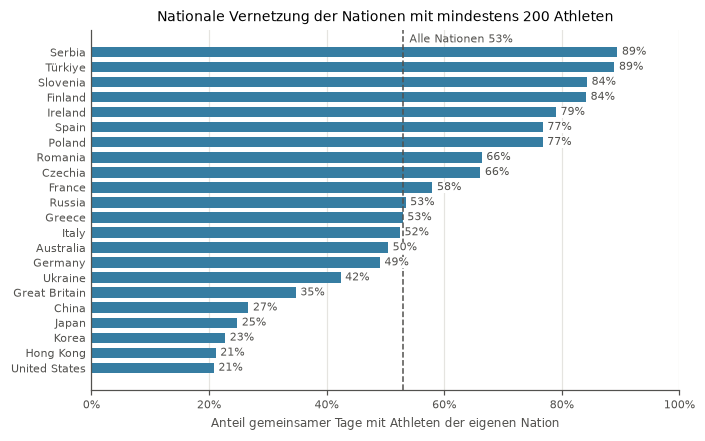

22 Nationen mit mindestens 200 Athleten.


In [12]:
LARGE_NATION = 200
nation_view = pd.DataFrame({
    'athletes': athletes_per_nation,
    'internal': internal_weight.reindex(athletes_per_nation.index, fill_value=0),
    'external': pd.Series(dict(N.degree(weight='weight'))),
})
nation_view['internal_share'] = (
    2 * nation_view['internal'] / (2 * nation_view['internal'] + nation_view['external'])
)
large_nations = nation_view[nation_view['athletes'] >= LARGE_NATION].sort_values('internal_share')
overall_share = internal_weight.sum() / total_weight
# Der gewichtete Mittelwert der Nationen entspricht dem Gesamtanteil.
assert np.isclose((2 * nation_view['internal']).sum()
                  / (2 * nation_view['internal'] + nation_view['external']).sum(), overall_share)

with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 3.9), layout='constrained')
    ax.barh(large_nations.index, large_nations['internal_share'], color=COLOR, height=0.7)
    ax.axvline(overall_share, color='#52514e', linestyle='--', linewidth=1)
    ax.annotate(f'Alle Nationen {overall_share:.0%}', (overall_share, 1.0),
                xycoords=('data', 'axes fraction'), xytext=(4, -2),
                textcoords='offset points', va='top', fontsize=7, color='#52514e')
    for name, share in large_nations['internal_share'].items():
        ax.annotate(f'{share:.0%}', (share, name), xytext=(3, 0),
                    textcoords='offset points', va='center', fontsize=7, color='#52514e',
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.3})
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set(xlim=(0, 1), xlabel='Anteil gemeinsamer Tage mit Athleten der eigenen Nation',
           title=f'Nationale Vernetzung der Nationen mit mindestens {LARGE_NATION} Athleten')
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)
    fig.savefig(REPORT_DIR / '04_nationen_intern.pdf', bbox_inches='tight')
    plt.show()

print(f'{len(large_nations)} Nationen mit mindestens {LARGE_NATION} Athleten.')

### Darstellung des Nationennetzes

Mit einer Density von 0.68 wäre das vollständige Nationennetz unlesbar. Wir zeigen deshalb die Nationen mit mindestens 50 Athleten und für jede Nation ihre drei stärksten Partner. Die Stärke wird pro Athlet der Partnernation gemessen, damit grosse Nationen nicht automatisch dominieren. Die Farbe zeigt den Anteil nationaler Verbindungen.

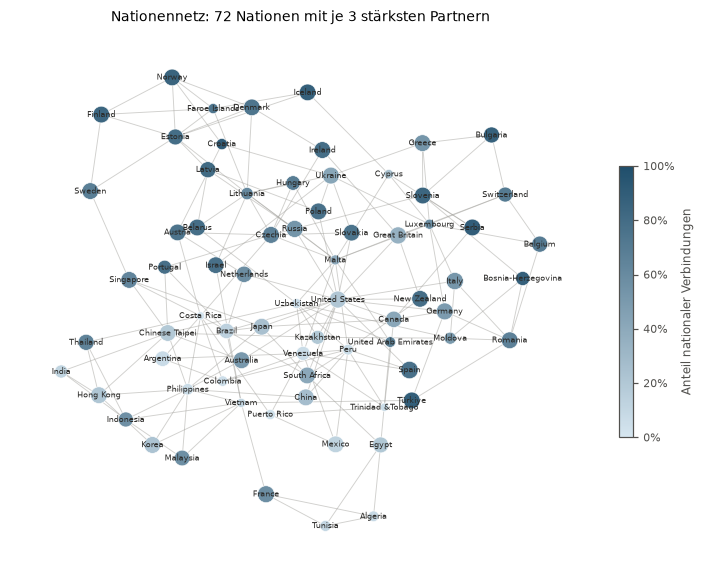

In [13]:
MIN_ATHLETES, TOP_PARTNERS = 50, 3
core = N.subgraph(athletes_per_nation.index[athletes_per_nation >= MIN_ATHLETES])
backbone = nx.Graph()
backbone.add_nodes_from(sorted(core))  # feste Reihenfolge für das Layout
for name in backbone:
    # Gewicht pro Athlet der Partnernation, für jede Nation gleich normiert.
    partners = sorted(core[name], reverse=True,
                      key=lambda other: core[name][other]['weight'] / athletes_per_nation[other])
    backbone.add_edges_from((name, other) for other in partners[:TOP_PARTNERS])
assert nx.is_connected(backbone)

share_cmap = LinearSegmentedColormap.from_list('share', ['#d6e6f0', '#1f4e6b'])
backbone_positions = nx.kamada_kawai_layout(backbone)
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 5.2), layout='constrained')
    nx.draw_networkx_edges(backbone, backbone_positions, ax=ax, width=0.6,
                           alpha=0.5, edge_color=MUTED)
    nodes = list(backbone)
    drawn = nx.draw_networkx_nodes(
        backbone, backbone_positions, ax=ax, nodelist=nodes,
        node_size=[0.6 * athletes_per_nation[name] for name in nodes],
        node_color=[nation_view.loc[name, 'internal_share'] for name in nodes],
        cmap=share_cmap, vmin=0, vmax=1, edgecolors='white', linewidths=0.4,
    )
    nx.draw_networkx_labels(backbone, backbone_positions, ax=ax, font_size=5.5,
                            font_color='#2b2a28')
    colorbar = fig.colorbar(drawn, ax=ax, shrink=0.5, format=PercentFormatter(xmax=1))
    colorbar.set_label('Anteil nationaler Verbindungen')
    ax.set_title(f'Nationennetz: {len(backbone)} Nationen mit je {TOP_PARTNERS} stärksten Partnern')
    ax.axis('off')
    fig.savefig(REPORT_DIR / '04_nationennetz.pdf', bbox_inches='tight')
    plt.show()

Das Nationennetz ist mit einer Density von rund 0.68 sehr dicht: Rund zwei Drittel aller Nationenpaare teilen über einzelne Athleten Veranstaltungstage, insbesondere an internationalen Meisterschaften. Die stärksten Paare betreffen die USA sowie benachbarte Länder in Asien, rohe Gewichte bevorzugen aber grosse Nationen. Im reduzierten Nationennetz bilden sich regionale Gruppen, etwa Skandinavien mit dem Baltikum, Südosteuropa, Süd- und Ostasien sowie Frankreich mit Nordafrika. Die USA liegen zentral.

43.1 % der Kanten verbinden Athleten derselben Nation (53.1 % des Gewichts), bei zufällig verbundenen Athletenpaaren wären nur 1.2 % zu erwarten. Der Hypothesentest bestätigt diese nationale Prägung: Keine der 10'000 Permutationen erreicht mehr als 1.3 % (p < 0.0001, r = 0.25). Das passt zu nationalen Meisterschaften. Zwischen gleich grossen Nationen unterscheidet sich der Anteil deutlich: In Serbien, der Türkei, Slowenien und Finnland teilen die Athleten über 80 % ihrer Tage mit Landsleuten, in den USA, Hongkong, Korea, Japan und China nur 21 bis 27 %. Diese Nationen sind in den TOP100-Listen vermutlich vor allem mit international startenden Athleten vertreten.

## 4.9 Contextual View: Schweiz

Die Contextual View kombiniert beide Sichten: Die Schweizer Athleten bleiben einzelne Knoten (Local View), alle übrigen Athleten werden nach Profilnation zusammengefasst (Global View). So wird sichtbar, wie einzelne Schweizer mit anderen Nationen verbunden sind.

In [14]:
FOCUS = 'Switzerland'
focus_athletes = nation.index[nation.eq(FOCUS)]

# Jede Kante aus Sicht eines Schweizer Athleten; Nachbarn werden auf ihre Nation reduziert.
context = pd.DataFrame(
    [(athlete, nation[other], G_work[athlete][other]['weight'])
     for athlete in focus_athletes for other in G_work[athlete]],
    columns=['athlete', 'nation', 'weight'],
)
foreign = context[context['nation'].ne(FOCUS)]
nations_per_athlete = foreign.groupby('athlete')['nation'].nunique()
athlete_nation_days = context.groupby(['athlete', 'nation'])['weight'].sum().unstack(fill_value=0)
home_days = athlete_nation_days.pop(FOCUS)
home_share = home_days / (home_days + athlete_nation_days.sum(axis=1))

display(pd.Series({
    'Schweizer Athleten': f'{len(focus_athletes)}',
    'mit Verbindungen im Arbeitsnetz': f"{context['athlete'].nunique()}",
    'mit Verbindungen ins Ausland': f'{len(nations_per_athlete)}',
    'Nationen pro Athlet (Median)': f'{nations_per_athlete.median():.0f}',
    'Nationen pro Athlet (25 %–75 %)': f'{nations_per_athlete.quantile(0.25):.0f}–'
                                       f'{nations_per_athlete.quantile(0.75):.0f}',
    'Anteil gemeinsamer Tage mit Schweizern (gesamt)': f"{nation_view.loc[FOCUS, 'internal_share']:.0%}",
    'Anteil gemeinsamer Tage mit Schweizern (Median pro Athlet)': f'{home_share.median():.0%}',
}, name='Contextual View').to_frame())

display(foreign.groupby('nation')['weight'].sum().nlargest(5)
        .rename('Gemeinsame Tage mit Schweizern').to_frame())
display(pd.DataFrame({
    'Athlet': names[nations_per_athlete.nlargest(5).index],
    'Nationen': nations_per_athlete.nlargest(5),
    'Gemeinsame Tage im Ausland': foreign.groupby('athlete')['weight'].sum(),
}).dropna().astype({'Nationen': int, 'Gemeinsame Tage im Ausland': int})
        .sort_values('Nationen', ascending=False).reset_index(drop=True))

,Contextual View
Schweizer Athleten,160
mit Verbindungen im Arbeitsnetz,155
mit Verbindungen ins Ausland,152
Nationen pro Athlet (Median),7
Nationen pro Athlet (25 %–75 %),4–15
Anteil gemeinsamer Tage mit Schweizern (gesamt),70%
Anteil gemeinsamer Tage mit Schweizern (Median pro Athlet),82%


,Gemeinsame Tage mit Schweizern
nation,
Liechtenstein,596.0
Great Britain,323.0
Belgium,270.0
Austria,201.0
Morocco,195.0


,Athlet,Nationen,Gemeinsame Tage im Ausland
0,"PONTI, Noe",97,521
1,"HALDEMANN, Alexandre",89,409
2,"RAEUFTLIN, Lukas Peter",68,248
3,"UGOLKOVA, Maria",52,239
4,"DIEZI, Dominique",51,203


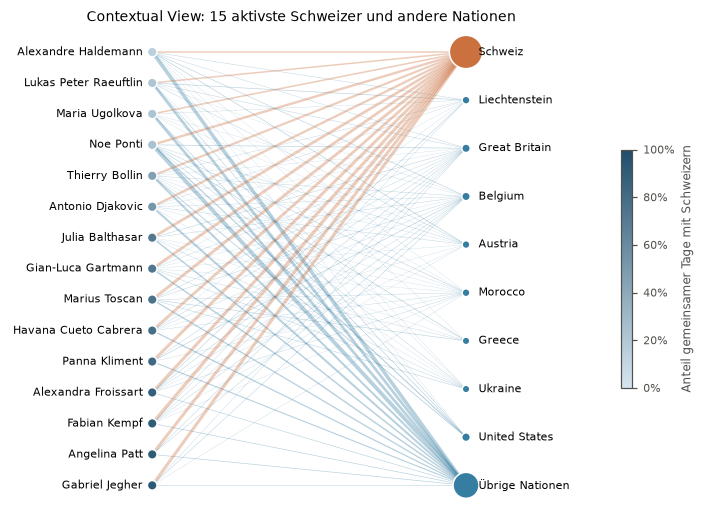

In [15]:
TOP_ATHLETES, TOP_NATIONS = 15, 8
# Die aktivsten Schweizer, sortiert von international zu national vernetzt.
shown = (home_days + athlete_nation_days.sum(axis=1)).nlargest(TOP_ATHLETES).index
shown = home_share[shown].sort_values().index
top_nations = athlete_nation_days.sum().nlargest(TOP_NATIONS).index
context_matrix = athlete_nation_days.loc[shown, top_nations].assign(
    **{'Übrige Nationen': athlete_nation_days.loc[shown].drop(columns=top_nations).sum(axis=1)}
)
context_matrix.insert(0, 'Schweiz', home_days[shown])
targets = list(context_matrix.columns)

y_athletes = np.linspace(1, 0, len(shown))
y_targets = np.linspace(1, 0, len(targets))
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 4.6), layout='constrained')
    for i, athlete in enumerate(shown):
        for j, target in enumerate(targets):
            days = context_matrix.loc[athlete, target]
            if days > 0:
                ax.plot([0, 1], [y_athletes[i], y_targets[j]], alpha=0.35,
                        color='#cb7140' if target == 'Schweiz' else COLOR,
                        linewidth=0.12 * np.sqrt(days), solid_capstyle='round')
    drawn = ax.scatter(np.zeros(len(shown)), y_athletes, s=40, c=home_share[shown],
                       cmap=share_cmap, vmin=0, vmax=1, edgecolors='white', zorder=3)
    ax.scatter(np.ones(len(targets)), y_targets, s=20 + 0.15 * context_matrix.sum().to_numpy(),
               c=['#cb7140'] + [COLOR] * (len(targets) - 1), edgecolors='white', zorder=3)
    for y, athlete in zip(y_athletes, shown):
        last, first = names[athlete].split(', ', 1)
        ax.text(-0.03, y, f'{first} {last.title()}', ha='right', va='center', fontsize=7)
    for y, target in zip(y_targets, targets):
        ax.text(1.04, y, target, ha='left', va='center', fontsize=7)
    colorbar = fig.colorbar(drawn, ax=ax, shrink=0.5, format=PercentFormatter(xmax=1))
    colorbar.set_label('Anteil gemeinsamer Tage mit Schweizern')
    ax.set_xlim(-0.45, 1.4)
    ax.set_title(f'Contextual View: {TOP_ATHLETES} aktivste Schweizer und andere Nationen')
    ax.axis('off')
    fig.savefig(REPORT_DIR / '04_contextual_schweiz.pdf', bbox_inches='tight')
    plt.show()

Die meisten Schweizer teilen ihre Tage vor allem mit Landsleuten (Median 82 %) und nur mit Athleten weniger Nationen. In der Abbildung sind die unteren, national vernetzten Athleten überwiegend mit der Schweiz verbunden. Einzelne Athleten der internationalen Spitze wie Noè Ponti und Alexandre Haldemann verbinden die Schweiz dagegen mit fast hundert Nationen, vor allem über die vielen Nationen unter „Übrige Nationen“, auf die 71 % aller Auslandstage der Schweizer entfallen. Die internationale Einbindung hängt damit an wenigen Personen. Wichtigster ausländischer Partner ist Liechtenstein, dessen Athleten vermutlich regelmässig an Schweizer Wettkämpfen starten.

## 4.10 Ego-Netzwerk von Michael Phelps

Das Ego-Netzwerk enthält Michael Phelps, alle seine Nachbarn im Arbeitsnetz (Alters) und die Kanten zwischen diesen. Über die Zuordnungstabelle prüfen wir, an welchen Wettkämpfen die Verbindungen entstehen.

In [16]:
ego_nodes = names.index[names.eq('PHELPS, Michael')]
assert len(ego_nodes) == 1
ego = ego_nodes[0]

# Knoten sortieren: Die Reihenfolge von Subgraphen hängt sonst vom String-Hashing ab
# und das Layout wäre trotz Seed nicht reproduzierbar.
ego_view = nx.ego_graph(G_work, ego)
E = nx.Graph()
E.add_nodes_from(sorted(ego_view))
E.add_edges_from(ego_view.edges(data=True))
alters = [node for node in E if node != ego]
A = E.subgraph(alters)
alter_nation = nation.loc[alters]
alter_birth = pd.Series(nx.get_node_attributes(A, 'birth_year'))

display(pd.Series({
    'Nachbarn im vollständigen Graphen': f'{G.degree(ego)}',
    'Alters im Arbeitsnetz': f'{len(alters)}',
    'Kanten zwischen Alters': f"{A.number_of_edges():,}".replace(',', "'"),
    'Density unter Alters': f'{nx.density(A):.2f}',
    'Density des Arbeitsnetzes': f'{work_density:.4f}',
    'Nationen der Alters': f'{alter_nation.nunique()}',
    'Anteil USA': f"{alter_nation.eq('United States').mean():.0%}",
    'Geburtsjahre (25 %–75 %)': f'{alter_birth.quantile(0.25):.0f}–{alter_birth.quantile(0.75):.0f}',
}, name='Ego-Netzwerk').to_frame())

athlete_events = pd.read_parquet(EVENTS_PATH, columns=['athlete_node', 'best_name', 'event_id'])
ego_days = athlete_events.loc[athlete_events['athlete_node'].eq(ego), 'event_id']
shared_days = athlete_events[athlete_events['event_id'].isin(ego_days)
                             & athlete_events['athlete_node'].isin(alters)]
display(shared_days.groupby('best_name')['athlete_node'].nunique()
        .nlargest(5).rename('Alters mit gemeinsamem Tag').to_frame())

,Ego-Netzwerk
Nachbarn im vollständigen Graphen,708
Alters im Arbeitsnetz,168
Kanten zwischen Alters,3'700
Density unter Alters,0.26
Density des Arbeitsnetzes,0.0041
Nationen der Alters,61
Anteil USA,17%
Geburtsjahre (25 %–75 %),nan–nan


,Alters mit gemeinsamem Tag
best_name,
FINA: 13th World Championships,121
XXIX Olympic Games,51
FINA: World Cup No 4 - 2009 Series,26
Duel in the Pool,19
FINA: World Cup No 4 - 2011 Series,18


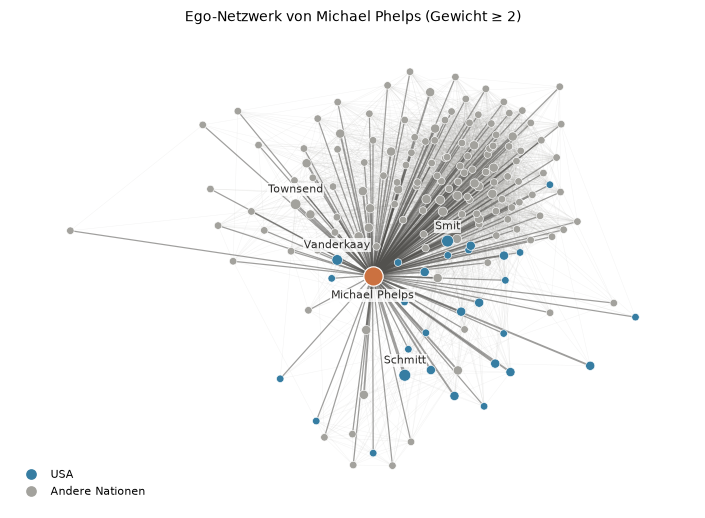

In [17]:
ego_weight = pd.Series({node: E[ego][node]['weight'] for node in alters})
is_usa = alter_nation.eq('United States')
positions = nx.spring_layout(E, seed=SEED, pos={ego: (0, 0)}, fixed=[ego], iterations=100)

with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 4.6), layout='constrained')
    nx.draw_networkx_edges(A, positions, ax=ax, width=0.3, alpha=0.12, edge_color=MUTED)
    nx.draw_networkx_edges(E, positions, ax=ax, edgelist=[(ego, node) for node in alters],
                           width=[0.4 * w for w in ego_weight], alpha=0.55, edge_color='#52514e')
    for usa, color in [(False, MUTED), (True, COLOR)]:
        nodes = ego_weight.index[is_usa.eq(usa)]
        nx.draw_networkx_nodes(E, positions, ax=ax, nodelist=nodes, node_color=color,
                               node_size=(12 * ego_weight[nodes]).tolist(),
                               edgecolors='white', linewidths=0.4)
    nx.draw_networkx_nodes(E, positions, ax=ax, nodelist=[ego], node_color='#cb7140',
                           node_size=160, edgecolors='white', linewidths=0.8)
    # Ego unterhalb, die stärksten Alters oberhalb ihres Knotens beschriften.
    labels = [(ego, 'Michael Phelps', -9)] + [
        (node, names[node].split(',')[0].title(), 6)
        for node in ego_weight[ego_weight >= 4].index
    ]
    for node, text, offset in labels:
        ax.annotate(text, positions[node], xytext=(0, offset), textcoords='offset points',
                    ha='center', va='top' if offset < 0 else 'bottom', fontsize=7,
                    color='#2b2a28', bbox={'facecolor': 'white', 'edgecolor': 'none',
                                           'alpha': 0.8, 'pad': 0.5})
    ax.legend(handles=[
        Line2D([], [], marker='o', linestyle='', color=COLOR, label='USA'),
        Line2D([], [], marker='o', linestyle='', color=MUTED, label='Andere Nationen'),
    ], loc='lower left', frameon=False, fontsize=7)
    ax.set_title('Ego-Netzwerk von Michael Phelps (Gewicht ≥ 2)')
    ax.axis('off')
    fig.savefig(REPORT_DIR / '04_ego_phelps.pdf', bbox_inches='tight')
    plt.show()

Im vollständigen Graphen hat Phelps 708 Nachbarn, im Arbeitsnetz bleiben 168 mit mindestens zwei gemeinsamen Tagen. Nur 17 % davon stammen aus den USA; die Alters verteilen sich auf 61 Nationen und gehören überwiegend derselben Generation an. Die meisten Verbindungen entstehen an der Weltmeisterschaft 2009 in Rom und den Olympischen Spielen 2008 in Peking, also an grossen internationalen Meisterschaften mit mehreren Wettkampftagen. Die stärksten Verbindungen mit vier oder fünf Tagen bestehen zu Teamkollegen aus den USA sowie zu Darian Townsend.

Die Alters sind untereinander mit einer Density von 0.26 viel dichter verbunden als das Arbeitsnetz (0.0041). Das ist eine Folge der Modellierung: Jeder Veranstaltungstag verbindet alle dort erfassten Athleten vollständig. Ein Ego-Netzwerk zeigt deshalb vor allem, an welchen Veranstaltungen ein Athlet seine Bestleistungen erzielte, und nicht persönliche Kontakte.